In [1]:
import os
from typing import List
from pydantic import BaseModel
from dotenv import load_dotenv

from langchain_community.vectorstores import FAISS
from langchain_community.document_loaders import WebBaseLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain.chat_models import init_chat_model
from langchain_huggingface import HuggingFaceEmbeddings   # OpenAIEmbeddings ki jagah
from langchain_core.documents import Document             # langchain.schema ab purana ho gaya
from langgraph.graph import StateGraph, END

C:\Users\Adit Sharma\AppData\Local\Temp\ipykernel_7712\2514776063.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS
USER_AGENT environment variable not set, consider setting it to identify your requests.


In [2]:
load_dotenv()
os.environ["GROQ_API_KEY"] = os.getenv("groq_api") or os.getenv("groq_api", "")
os.environ["HF_TOKEN"] = os.getenv("hf_token", "")
os.environ["USER_AGENT"] = "agentic-rag-notebook"   # WebBaseLoader ki warning band karne ke liye

llm = init_chat_model("groq:openai/gpt-oss-20b")
llm


ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000015D017C7380>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000015D019741A0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [3]:
urls = [
    "https://lilianweng.github.io/posts/2023-06-23-agent/",
    "https://lilianweng.github.io/posts/2024-04-12-diffusion-video/",
]

docs = []
for url in urls:
    docs.extend(WebBaseLoader(url).load())

len(docs)


2

In [4]:
splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
split_docs = splitter.split_documents(docs)

embedding = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
vectorstore = FAISS.from_documents(split_docs, embedding)
retriever = vectorstore.as_retriever()

retriever.invoke("What are agents")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[Document(id='967a6714-5abf-4cf9-b391-165e994e53c5', metadata={'source': 'https://lilianweng.github.io/posts/2023-06-23-agent/', 'title': "LLM Powered Autonomous Agents | Lil'Log", 'description': 'Building agents with LLM (large language model) as its core controller is a cool concept. Several proof-of-concepts demos, such as AutoGPT, GPT-Engineer and BabyAGI, serve as inspiring examples. The potentiality of LLM extends beyond generating well-written copies, stories, essays and programs; it can be framed as a powerful general problem solver.\nAgent System Overview\nIn a LLM-powered autonomous agent system, LLM functions as the agent’s brain, complemented by several key components:\n\nPlanning\n\nSubgoal and decomposition: The agent breaks down large tasks into smaller, manageable subgoals, enabling efficient handling of complex tasks.\nReflection and refinement: The agent can do self-criticism and self-reflection over past actions, learn from mistakes and refine them for future steps, 

In [5]:
class RAGState(BaseModel):
    question: str
    retrieved_docs: List[Document] = []
    answer: str = ""


In [6]:
def retrieve_docs(state: RAGState):
    docs = retriever.invoke(state.question)
    return {"retrieved_docs": docs}

def generate_answer(state: RAGState):
    context = "\n\n".join(doc.page_content for doc in state.retrieved_docs)
    prompt = (
        "Answer the question based on the context.\n\n"
        f"Context:\n{context}\n\nQuestion: {state.question}"
    )
    response = llm.invoke(prompt)
    return {"answer": response.content}


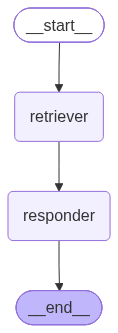

In [7]:
builder = StateGraph(RAGState)

builder.add_node("retriever", retrieve_docs)
builder.add_node("responder", generate_answer)

builder.set_entry_point("retriever")
builder.add_edge("retriever", "responder")
builder.add_edge("responder", END)

graph = builder.compile()
graph


In [8]:
user_question = "What is the concept of agent loop in autonomous agents?"
final_state = graph.invoke(RAGState(question=user_question))

print("✅ Final Answer:\n", final_state["answer"])


✅ Final Answer:
 **Agent loop** – the core, repeating cycle that lets a generative autonomous agent act in a world, learn from its experiences, and keep improving its behaviour.

| Step | What happens | Why it matters |
|------|--------------|----------------|
| **1. Perceive / Observe** | The agent receives raw sensory data (text, images, sensor readings, or other agents’ messages). | Gives the agent the current state of the world. |
| **2. Update internal state / memory** | The observation is stored or merged with the agent’s existing memory (often a tree‑structured knowledge graph). Relationships between agents and other entities are updated. | Maintains a coherent, up‑to‑date model of the environment that the LLM can reason about. |
| **3. Plan / decide** | The LLM, acting as the brain, generates a plan or next action conditioned on the updated state and any constraints or goals. | Turns raw data into a concrete, goal‑aligned action. |
| **4. Act** | The plan is executed: the agent